# Session 7 — Convolutional networks, transfer learning, and the scoreboard

**Repository:** https://github.com/jcole-jpg/Computer-Vision-and-Speech-Recognition (module `src/milk10k/cnn.py`, this notebook is generated by `scripts/build_session7_notebook.py`).

**Class lab.** (1) The by-hand numbers of Part 1, checked in PyTorch. (2) A CNN built from scratch. (3) A pretrained ResNet-18
fine-tuned with three strategies of increasing freedom. **Mini-challenge (slide 29).** Unfreeze `layer3` as well: is it worth the cost?
**Homework (slide 30).** (1) The Sessions 5–7 scoreboard, validation and test macro-F1, and the best model with its number.
(2) How EfficientNet / DenseNet differ from ResNet. (3) Optional: fine-tune the whole network (strategy 3).

**Protocol, fixed before any number was looked at.** The same committed lesion-level splits as Sessions 5–6 (`artifacts/splits`, seed 42:
3,742 train / 749 val / 749 test lesions); the dermoscopic image of each lesion, stretched to 224×224; ImageNet normalisation;
class-weighted cross-entropy; Adam; 10 epochs for every network; the epoch with the best **validation** macro-F1 is kept.
The **test split is scored once, in section 6**, after every choice has been made.

In [1]:
# --- setup: find the repo root from wherever the notebook is opened -----------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import milk10k as mk
from milk10k import features as F

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import torch, torch.nn as nn, torch.nn.functional as Fn, torchvision
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from milk10k import cnn, metrics

OUT = mk.config.ARTIFACT_DIR / "session07"
FIG = mk.config.FIG_DIR
OUT.mkdir(parents=True, exist_ok=True)
dev = cnn.device()
print(f"torch {torch.__version__} · torchvision {torchvision.__version__} · device {dev}")

torch 2.14.0 · torchvision 0.29.0 · device mps


## 1. Part 1 by hand, checked in code

**1a. The parameter explosion (slide 7).** One hidden layer of 128 neurons on a flattened 224×224 RGB image against one conv layer of 32 filters of 3×3.

In [2]:
dense = 224 * 224 * 3 * 128 + 128
conv = 3 * 3 * 3 * 32 + 32
assert dense == sum(p.numel() for p in nn.Linear(224 * 224 * 3, 128).parameters())
assert conv == sum(p.numel() for p in nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1).parameters())
print(f"dense 150,528 -> 128 : {dense:,} weights\nconv  32 x (3x3x3)    : {conv:,} weights\nratio: {dense / conv:,.0f}x fewer")

dense 150,528 -> 128 : 19,267,712 weights
conv  32 x (3x3x3)    : 896 weights
ratio: 21,504x fewer


**1b. Convolution, ReLU and max pooling (slides 8 and 13).** `F.conv2d` slides the window and multiplies-and-adds without flipping the kernel, which is the by-hand rule of the slide.

In [3]:
toy = torch.tensor([[100, 100, 100, 100, 100]] * 2 + [[100, 100, 10, 10, 10]] * 3, dtype=torch.float32)       # lesion = 10 on a skin of 100
sobel_x = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32)
edge = Fn.conv2d(toy[None, None], sobel_x[None, None])[0, 0]
print(edge.int().numpy())
assert edge.int().tolist() == [[-90, -90, 0], [-270, -270, 0], [-360, -360, 0]]           # the slide's output, top-left = -90

fmap = torch.tensor([[-3, 5, 2, 0], [1, 8, -1, 4], [0, -2, 6, 7], [3, 1, -4, 2]], dtype=torch.float32)
pooled = Fn.max_pool2d(Fn.relu(fmap)[None, None], kernel_size=2)[0, 0]
print(pooled.int().numpy())
assert pooled.int().tolist() == [[8, 4], [3, 7]]

[[ -90  -90    0]
 [-270 -270    0]
 [-360 -360    0]]
[[8 4]
 [3 7]]


**1c. Tracing shapes and parameters (slide 15).** `out = ⌊(in + 2·pad − kernel) / stride⌋ + 1`, layer by layer, against what PyTorch builds.

In [4]:
net = cnn.slide_cnn()
x, side, rows = torch.zeros(1, 3, 224, 224), 224, []
for layer in net:
    x = layer(x)
    if isinstance(layer, nn.Conv2d):
        side = (side + 2 * layer.padding[0] - layer.kernel_size[0]) // layer.stride[0] + 1          # the formula
    elif isinstance(layer, nn.MaxPool2d):
        side = (side - layer.kernel_size) // layer.stride + 1
    rows.append({"layer": str(layer).split("(")[0], "output": "x".join(map(str, x.shape[1:])),
                 "params": sum(p.numel() for p in layer.parameters())})
    if x.dim() == 4:
        assert x.shape[-1] == side, "PyTorch and the formula disagree"
trace = pd.DataFrame(rows)
print(trace.to_string(index=False))
total = trace["params"].sum()
print(f"total {total:,}   share in the last Linear: {trace['params'].iloc[-1] / total:.0%}   "
      f"with global average pooling instead: {32 * 3 + 3}")
assert total == 306_147

    layer     output  params
   Conv2d 16x224x224     448
     ReLU 16x224x224       0
MaxPool2d 16x112x112       0
   Conv2d 32x112x112    4640
     ReLU 32x112x112       0
MaxPool2d   32x56x56       0
  Flatten     100352       0
   Linear          3  301059
total 306,147   share in the last Linear: 98%   with global average pooling instead: 99


## 2. The data, as tensors

Each dermoscopic image is read once, stretched to 224×224 (so nothing at the frame edge is cropped) and kept in memory as `uint8`.
Training batches are augmented on the fly (Session 3's recipe: flips, quarter turns, mild brightness / contrast): more variety, same labels.
Validation and test images are never augmented.

{'train': (3742, 3, 224, 224), 'val': (749, 3, 224, 224), 'test': (749, 3, 224, 224)} 3 s
               train  val  test
Benign          1058  213   212
Indeterminate     89   17    17
Malignant       2595  519   520
class weights {'Benign': 1.1799999475479126, 'Indeterminate': 14.010000228881836, 'Malignant': 0.47999998927116394}


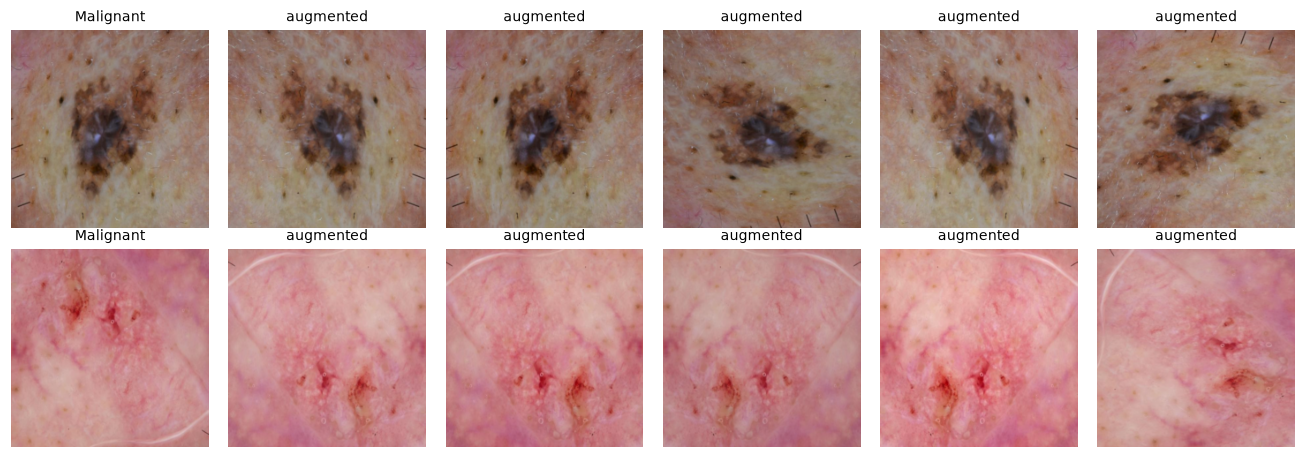

In [5]:
frames = F.load_lesion_splits()
order = ["train", "val", "test"]
t0 = time.perf_counter()
X_all = cnn.image_tensors(pd.concat([frames[k]["derm_id"] for k in order]))
Xs = dict(zip(order, X_all.split([len(frames[k]) for k in order])))
ys = {k: cnn.labels_tensor(frames[k]["diagnosis_1"]) for k in order}
w = len(ys["train"]) / (3 * torch.bincount(ys["train"]).float())                 # Session 6's inverse-frequency weights
print({k: tuple(v.shape) for k, v in Xs.items()}, f"{time.perf_counter() - t0:.0f} s")
print(pd.DataFrame({k: pd.Series(ys[k].numpy()).map(dict(enumerate(cnn.CLASSES))).value_counts() for k in order}).loc[cnn.CLASSES])
print("class weights", dict(zip(cnn.CLASSES, w.numpy().round(2).tolist())))

# what the augmentation does to one training image: 1 original + 5 draws
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
gen = torch.Generator().manual_seed(7)
for row, i in enumerate([0, 40]):
    src = Xs["train"][i:i + 1]
    axes[row, 0].imshow(src[0].permute(1, 2, 0)); axes[row, 0].set_title(cnn.CLASSES[ys["train"][i]], fontsize=9)
    for j in range(1, 6):
        a = cnn.augment(src, gen) * cnn._STD + cnn._MEAN
        axes[row, j].imshow(a[0].permute(1, 2, 0).clamp(0, 1)); axes[row, j].set_title("augmented", fontsize=9)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.savefig(FIG / "s7_augmentation.png", dpi=110); plt.show()

## 3. A CNN from scratch

Three networks trained from random weights, all parameters at lr 1e-3:

* **slide-15 net**: the 306,147-weight network traced above (conv-pool-conv-pool-flatten-linear);
* **scratch CNN**: four conv-BatchNorm-ReLU-pool blocks, then each map averaged to one number (global average pooling) and a 256→3 head;
* **ResNet-18 from random weights**: the full 11.2 M-weight architecture without ImageNet, the control for "is the pretraining what matters?".

In [6]:
COMMON = dict(epochs=10, batch_size=32, class_weights=w)
runs = {}

def run(name, model, seed=0, lr_head=1e-3, lr_backbone=1e-4):
    """Train (or reload) one network; keep its result, history and weights in `runs`."""
    print(f"{name}: {cnn.count_parameters(model)}")
    runs[name] = cnn.run_cached(name, model, Xs["train"], ys["train"], Xs["val"], ys["val"],
                                seed=seed, lr_head=lr_head, lr_backbone=lr_backbone, **COMMON)
    runs[name]["model"] = model

run("slide_cnn", cnn.slide_cnn(seed=0), lr_backbone=1e-3)
run("scratch_cnn", cnn.scratch_cnn(seed=0), lr_backbone=1e-3)
run("resnet18_random", cnn.resnet18(None, pretrained=False, seed=0), lr_backbone=1e-3)

slide_cnn: {'total': 306147, 'trainable': 306147, 'frozen': 0}
  slide_cnn: loaded the saved run (best epoch 3, val F1 0.564)
scratch_cnn: {'total': 389667, 'trainable': 389667, 'frozen': 0}
  scratch_cnn: loaded the saved run (best epoch 10, val F1 0.469)
resnet18_random: {'total': 11178051, 'trainable': 11178051, 'frozen': 0}
  resnet18_random: loaded the saved run (best epoch 4, val F1 0.510)


## 4. Transfer learning: how much to unfreeze (slide 23)

Pretrained ImageNet ResNet-18, `fc` replaced by a fresh `Linear(512, 3)`. The new head learns at **1e-3**, any unfrozen pretrained layer at **1e-4** (slide 24).
Frozen layers also keep their BatchNorm statistics (`set_train_mode`). Every run: same data, same augmentation, same 10 epochs, seed 0.

| strategy | trains | what it means |
|---|---|---|
| 1 feature extraction | `fc` | frozen backbone = 512 fixed features + a linear classifier |
| 2 partial | `layer4` + `fc` | the usual default for moderate data |
| 2b partial, deeper (mini-challenge) | `layer3` + `layer4` + `fc` | one more stage unfrozen |
| 3 full | everything | the optional homework |

In [7]:
SLUG = {"1 feature extraction (fc)": "s1_fc", "2 partial (layer4 + fc)": "s2_layer4",
        "2b partial (layer3 + layer4 + fc)": "s2b_layer3_4", "3 full fine-tuning": "s3_full"}
for strategy, prefixes in cnn.STRATEGIES.items():
    run(f"resnet18_{SLUG[strategy]}", cnn.resnet18(prefixes, seed=0))

def summary(names, labels=None):
    rows = [{"model": (labels or {}).get(n, n), "trainable params": runs[n]["trainable"],
             "s / epoch": runs[n]["seconds_per_epoch"], "best epoch": runs[n]["best_epoch"] + 1,
             "best val macro-F1": runs[n]["best_val_f1"]} for n in names]
    return pd.DataFrame(rows)

LABEL = {"slide_cnn": "slide-15 CNN (scratch)", "scratch_cnn": "scratch CNN, 4 blocks + GAP",
         "resnet18_random": "ResNet-18, random weights, full",
         **{f"resnet18_{v}": k for k, v in SLUG.items()}}
table = summary(LABEL, LABEL)
display(table.style.hide(axis="index").format({"trainable params": "{:,}", "s / epoch": "{:.1f}", "best val macro-F1": "{:.3f}"}))

resnet18_s1_fc: {'total': 11178051, 'trainable': 1539, 'frozen': 11176512}
  resnet18_s1_fc: loaded the saved run (best epoch 1, val F1 0.577)
resnet18_s2_layer4: {'total': 11178051, 'trainable': 8395267, 'frozen': 2782784}
  resnet18_s2_layer4: loaded the saved run (best epoch 10, val F1 0.654)


resnet18_s2b_layer3_4: {'total': 11178051, 'trainable': 10494979, 'frozen': 683072}
  resnet18_s2b_layer3_4: loaded the saved run (best epoch 4, val F1 0.684)
resnet18_s3_full: {'total': 11178051, 'trainable': 11178051, 'frozen': 0}
  resnet18_s3_full: loaded the saved run (best epoch 7, val F1 0.703)


model,trainable params,s / epoch,best epoch,best val macro-F1
slide-15 CNN (scratch),"306,147",27.6,3,0.564
"scratch CNN, 4 blocks + GAP","389,667",36.0,10,0.469
"ResNet-18, random weights, full","11,178,051",32.3,4,0.510
1 feature extraction (fc),"1,539",8.7,1,0.577
2 partial (layer4 + fc),"8,395,267",11.0,10,0.654
2b partial (layer3 + layer4 + fc),"10,494,979",15.0,4,0.684
3 full fine-tuning,"11,178,051",31.0,7,0.703


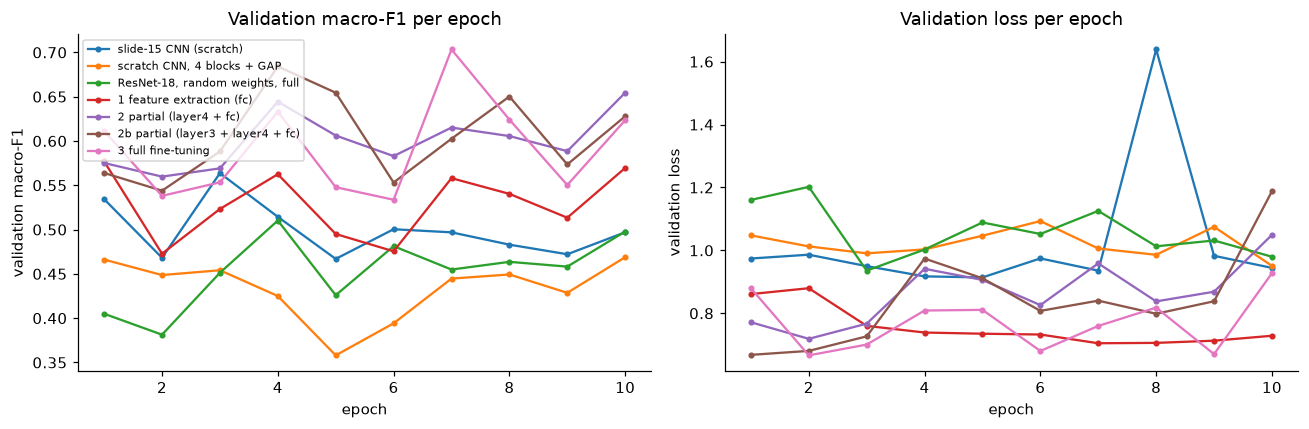

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, label in LABEL.items():
    h = runs[name]["history"]
    axes[0].plot(h.index + 1, h["val_f1"], marker="o", ms=3, label=label)
    axes[1].plot(h.index + 1, h["val_loss"], marker="o", ms=3, label=label)
axes[0].set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1 per epoch")
axes[1].set(xlabel="epoch", ylabel="validation loss", title="Validation loss per epoch")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "s7_curves.png", dpi=110); plt.show()

**Reading the table and the curves** (seed 0 only; section 5 says how much of a gap is noise).

* **Pretraining is what matters.** The same ResNet-18 from random weights reaches a validation macro-F1 of 0.510; started from ImageNet weights and fine-tuned in full it reaches 0.703.
  Nothing else differs (data, augmentation, epochs, optimiser). With 3,742 training lesions the network cannot learn good filters from scratch.
* **The small networks from scratch overfit.** The slide-15 net peaks at 0.564 in epoch 3 and then drifts down while its training loss keeps falling; the four-block GAP net never gets above 0.469.
* **A frozen backbone is a decent start, not the answer.** Feature extraction (1,539 trainable weights, 8.7 s per epoch) hits 0.577 in epoch 1 and then wanders: the 512 ImageNet features are fixed, only a linear read-out learns.
* **More freedom, better score, higher cost.** `layer4 + fc` 0.654 (11.0 s / epoch), `layer3 + layer4 + fc` 0.684 (15.0 s), the whole network 0.703 (31.0 s, about as slow as the random-weights ResNet).

## 5. Mini-challenge: unfreeze more and compare (slide 29)

Fresh pretrained ResNet-18, `layer3 + layer4 + fc` trainable, lr 1e-4, same 10 epochs, against `layer4 + fc`. Measured: trainable parameters, seconds per epoch
(median over the epochs, so the first epoch's GPU warm-up does not count), best **validation** macro-F1. The test split is not used here.
Validation macro-F1 is noisy (only 18 Indeterminate lesions in validation), so both configurations are repeated with two more seeds (1 and 2): a different head
initialisation and a different batch / augmentation order.

In [9]:
for seed in (1, 2):
    run(f"resnet18_s2_layer4_seed{seed}", cnn.resnet18(("layer4", "fc"), seed=seed), seed=seed)
    run(f"resnet18_s2b_layer3_4_seed{seed}", cnn.resnet18(("layer3", "layer4", "fc"), seed=seed), seed=seed)

mini = []
for label, base in [("layer4 + fc", "resnet18_s2_layer4"), ("layer3 + layer4 + fc", "resnet18_s2b_layer3_4")]:
    group = [base, f"{base}_seed1", f"{base}_seed2"]
    f1 = np.array([runs[n]["best_val_f1"] for n in group])
    mini.append({"unfrozen": label, "trainable params": runs[base]["trainable"],
                 "s / epoch": np.mean([runs[n]["seconds_per_epoch"] for n in group]),
                 "val F1 seed 0": f1[0], "val F1 mean of 3": f1.mean(), "std": f1.std(ddof=0), "min": f1.min(), "max": f1.max()})
mini = pd.DataFrame(mini)
display(mini.style.hide(axis="index").format({"trainable params": "{:,}", "s / epoch": "{:.1f}"}, precision=3))
a, b = mini.iloc[0], mini.iloc[1]
print(f"\nlayer3 adds {b['trainable params'] - a['trainable params']:,} trainable weights "
      f"(+{b['trainable params'] / a['trainable params'] - 1:.0%}) and {b['s / epoch'] - a['s / epoch']:+.1f} s per epoch "
      f"(+{b['s / epoch'] / a['s / epoch'] - 1:.0%}); validation macro-F1 {b['val F1 mean of 3'] - a['val F1 mean of 3']:+.3f} "
      f"(seed std {max(a['std'], b['std']):.3f}).")

resnet18_s2_layer4_seed1: {'total': 11178051, 'trainable': 8395267, 'frozen': 2782784}
  resnet18_s2_layer4_seed1: loaded the saved run (best epoch 9, val F1 0.651)
resnet18_s2b_layer3_4_seed1: {'total': 11178051, 'trainable': 10494979, 'frozen': 683072}


  resnet18_s2b_layer3_4_seed1: loaded the saved run (best epoch 10, val F1 0.677)
resnet18_s2_layer4_seed2: {'total': 11178051, 'trainable': 8395267, 'frozen': 2782784}
  resnet18_s2_layer4_seed2: loaded the saved run (best epoch 7, val F1 0.701)


resnet18_s2b_layer3_4_seed2: {'total': 11178051, 'trainable': 10494979, 'frozen': 683072}
  resnet18_s2b_layer3_4_seed2: loaded the saved run (best epoch 7, val F1 0.673)


unfrozen,trainable params,s / epoch,val F1 seed 0,val F1 mean of 3,std,min,max
layer4 + fc,"8,395,267",10.9,0.654,0.669,0.023,0.651,0.701
layer3 + layer4 + fc,"10,494,979",14.0,0.684,0.678,0.004,0.673,0.684



layer3 adds 2,099,712 trainable weights (+25%) and +3.1 s per epoch (+28%); validation macro-F1 +0.009 (seed std 0.023).


**Decision: not worth it.** Unfreezing `layer3` adds 2,099,712 trainable weights (+25 %) and about 3 s per epoch (10.9 s to 14.0 s, +28 %, mean of three seeds).
Validation macro-F1 moves from 0.669 to 0.678 (+0.009), while `layer4 + fc` alone varies by 0.023 (standard deviation) from seed to seed: seed 0 alone would have
suggested +0.030, seed 2 puts `layer4` ahead (0.701 against 0.673). The gain cannot be told apart from noise. The only consistent difference is a smaller spread with `layer3` unfrozen
(0.005 against 0.023), which three seeds can only hint at. The extra cost is small in absolute terms (about 30 s over ten epochs), so the answer is "no evidence it helps", not "harmful":
keep `layer4 + fc` as the default partial fine-tune. This decision uses the validation split only; the test split is first used in section 6, for the scoreboard.

## 6. The scoreboard, Sessions 5–7 (homework 1)

Every Session 7 network is scored on the test split here, **once**, from its best-validation weights (seed 0). Sessions 5 and 6 come from `artifacts/session05` and `artifacts/session06`
(same splits). The model to carry into Session 8 is picked by **validation** macro-F1 only; the test number is what it is.

In [10]:
def evaluate(model, split):
    return cnn.predict(model.to(dev), Xs[split], dev=dev)

S7 = ["slide_cnn", "scratch_cnn", "resnet18_random"] + [f"resnet18_{v}" for v in SLUG.values()]
rows7, logits = [], {}
for name in S7:
    lv, lt = evaluate(runs[name]["model"], "val"), evaluate(runs[name]["model"], "test")
    logits[name] = {"val": lv, "test": lt}
    sv, st = cnn.scores(ys["val"].numpy(), lv), cnn.scores(ys["test"].numpy(), lt)
    assert abs(sv["macro_f1"] - runs[name]["best_val_f1"]) < 1e-6, "restored weights must reproduce the validation score"
    pred = [cnn.CLASSES[i] for i in lt.argmax(1)]
    truth = [cnn.CLASSES[i] for i in ys["test"].numpy()]
    rows7.append({"session": 7, "model": LABEL[name], "trainable params": runs[name]["trainable"],
                  "val macro-F1": sv["macro_f1"], "test macro-F1": st["macro_f1"], "test accuracy": st["accuracy"],
                  "Malignant recall": recall_score(truth, pred, labels=["Malignant"], average="macro"),
                  "cost / lesion": metrics.expected_cost(truth, pred), "key": name})

old = pd.read_csv(mk.config.ARTIFACT_DIR / "session06" / "scoreboard.csv")
old["session"] = [5, 5, 5, 6, 6]
old = old.rename(columns={"parameters": "trainable params"})
board = pd.concat([old, pd.DataFrame(rows7)], ignore_index=True)
board = board[["session", "model", "trainable params", "val macro-F1", "test macro-F1", "test accuracy", "Malignant recall", "cost / lesion", "key"]]
display(board.drop(columns="key").style.hide(axis="index").format(
    {"trainable params": "{:,.0f}", "cost / lesion": "{:.2f}"}, precision=3, na_rep="–"))

session,model,trainable params,val macro-F1,test macro-F1,test accuracy,Malignant recall,cost / lesion
5,majority class,0,0.273,0.273,0.694,–,–
5,"Session 5 forest, 33 features",–,0.575,0.528,–,–,–
5,"Session 5 best: forest, derm + clinical (66)",–,0.568,0.536,0.744,–,–
6,Session 6 MLP 33-64-3 (33 features),"2,371",0.489,0.480,0.637,–,–
6,Session 6 MLP 3072-64-3 (raw 32x32x3 pixels),"196,867",0.549,0.484,0.724,–,–
7,slide-15 CNN (scratch),"306,147",0.564,0.483,0.717,0.779,7.59
7,"scratch CNN, 4 blocks + GAP","389,667",0.469,0.431,0.599,0.621,10.11
7,"ResNet-18, random weights, full","11,178,051",0.510,0.434,0.662,0.777,5.78
7,1 feature extraction (fc),"1,539",0.577,0.523,0.700,0.742,7.62
7,2 partial (layer4 + fc),"8,395,267",0.654,0.577,0.768,0.842,4.94


best overall by validation : 3 full fine-tuning  (val 0.703, test 0.598)
best Session 7 by validation: 3 full fine-tuning  (val 0.703, test 0.598)


3 full fine-tuning: test macro-F1 0.598, 95% CI [0.530, 0.662]
per-class recall: {'Benign': 0.698, 'Indeterminate': 0.412, 'Malignant': 0.788} | per-class F1: {'Benign': 0.648, 'Indeterminate': 0.326, 'Malignant': 0.822}


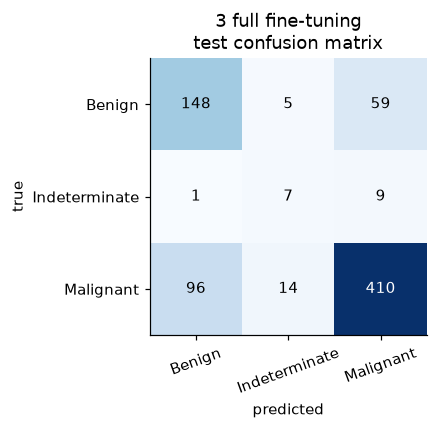

In [11]:
# The model to bring to Session 8: highest VALIDATION macro-F1 over all sessions (test plays no part in the choice).
best = board.sort_values("val macro-F1", ascending=False).iloc[0]
best7 = board[board["session"] == 7].sort_values("val macro-F1", ascending=False).iloc[0]
print(f"best overall by validation : {best['model']}  (val {best['val macro-F1']:.3f}, test {best['test macro-F1']:.3f})")
print(f"best Session 7 by validation: {best7['model']}  (val {best7['val macro-F1']:.3f}, test {best7['test macro-F1']:.3f})")

# uncertainty on the Session 7 pick: percentile bootstrap over the 749 test lesions (same recipe as Session 5)
def bootstrap_ci(y_true, y_pred, n=2000, seed=mk.config.SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y_true), (n, len(y_true)))
    return np.percentile([f1_score(y_true[i], y_pred[i], average="macro") for i in idx], [2.5, 97.5])

yt = ys["test"].numpy()
pt = logits[best7["key"]]["test"].argmax(1)
lo, hi = bootstrap_ci(yt, pt)
print(f"{best7['model']}: test macro-F1 {best7['test macro-F1']:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")
print("per-class recall:", dict(zip(cnn.CLASSES, recall_score(yt, pt, average=None).round(3).tolist())),
      "| per-class F1:", dict(zip(cnn.CLASSES, f1_score(yt, pt, average=None).round(3).tolist())))

cm = confusion_matrix(yt, pt)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set(xticks=range(3), yticks=range(3), xticklabels=cnn.CLASSES, yticklabels=cnn.CLASSES, xlabel="predicted", ylabel="true",
       title=f"{best7['model']}\ntest confusion matrix")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG / "s7_confusion.png", dpi=110); plt.show()

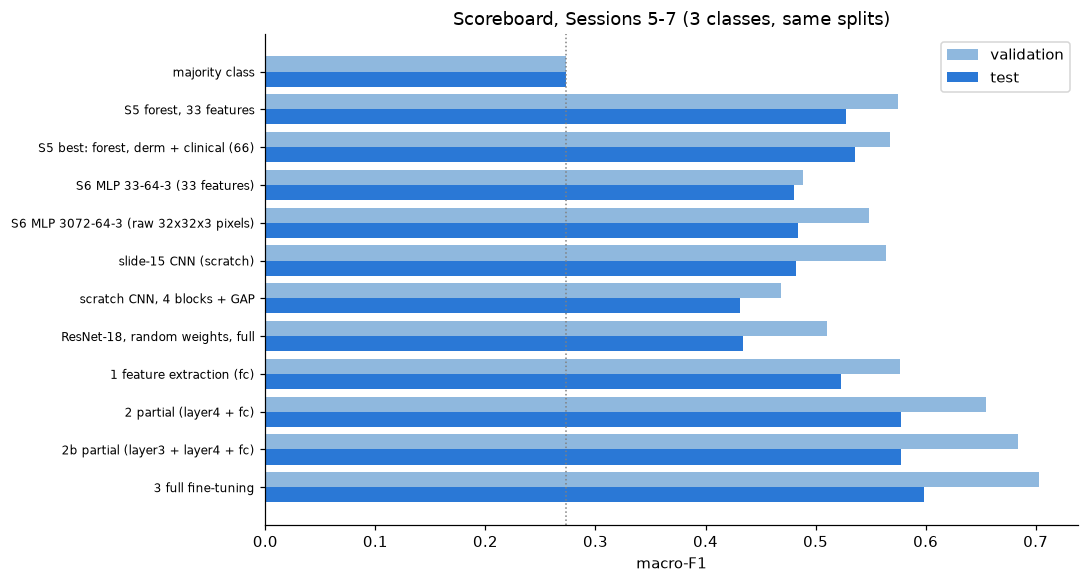

{
 "best_overall_by_val": {
  "model": "3 full fine-tuning",
  "val_macro_f1": 0.7033,
  "test_macro_f1": 0.5983
 },
 "best_session7_by_val": {
  "model": "3 full fine-tuning",
  "val_macro_f1": 0.7033,
  "test_macro_f1": 0.5983,
  "test_macro_f1_ci95": "[0.530, 0.662]",
  "test_accuracy": 0.7543
 },
 "epochs": 10,
 "seed": 0,
 "device": "mps",
 "torch": "2.14.0"
}


In [12]:
# the scoreboard as a picture: validation vs test macro-F1, by session
plot = board.copy()
plot["short"] = plot["model"].str.replace("Session 5 ", "S5 ").str.replace("Session 6 ", "S6 ")
fig, ax = plt.subplots(figsize=(10, 5.4))
pos = np.arange(len(plot))
ax.barh(pos - 0.2, plot["val macro-F1"], 0.4, label="validation", color="#8fb8de")
ax.barh(pos + 0.2, plot["test macro-F1"], 0.4, label="test", color="#2a78d6")
ax.set_yticks(pos); ax.set_yticklabels(plot["short"], fontsize=8); ax.invert_yaxis()
ax.axvline(0.273, color="grey", ls=":", lw=1); ax.set(xlabel="macro-F1", title="Scoreboard, Sessions 5-7 (3 classes, same splits)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "s7_scoreboard.png", dpi=110); plt.show()

board.drop(columns="key").round(4).to_csv(OUT / "scoreboard.csv", index=False)
mini.round(4).to_csv(OUT / "mini_challenge.csv", index=False)
summary_json = {
    "best_overall_by_val": {"model": best["model"], "val_macro_f1": round(float(best["val macro-F1"]), 4), "test_macro_f1": round(float(best["test macro-F1"]), 4)},
    "best_session7_by_val": {"model": best7["model"], "val_macro_f1": round(float(best7["val macro-F1"]), 4), "test_macro_f1": round(float(best7["test macro-F1"]), 4),
                             "test_macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]", "test_accuracy": round(float(best7["test accuracy"]), 4)},
    "epochs": 10, "seed": 0, "device": str(dev), "torch": torch.__version__,
}
(OUT / "scores.json").write_text(json.dumps(summary_json, indent=1))
print(json.dumps(summary_json, indent=1))

**Reading the scoreboard.**

* **The model to bring to Session 8: ResNet-18, fully fine-tuned (strategy 3).** Highest validation macro-F1 of everything in Sessions 5–7 (0.703), test macro-F1 **0.598**, 95 % CI [0.530, 0.662],
  accuracy 0.754. Per-class recall: Benign 0.70, Indeterminate 0.41, Malignant 0.79.
* **Against Session 5's forest (test 0.536, CI [0.472, 0.601]):** +0.062, but the intervals overlap, so on 749 test lesions this is a likely improvement, not a proven one.
  It is clearly above the Session 6 MLPs (0.480 and 0.484) and the networks trained from scratch (0.431 to 0.483), and pretraining is the reason: the same architecture from random weights scores 0.434.
* **The order of the pretrained strategies on test** is the order on validation (0.523, 0.577, 0.577, 0.598), but the gaps between the last three are within the seed noise measured in section 5.
  Choosing strategy 3 follows the rule fixed in advance (highest validation); `layer4 + fc` is statistically indistinguishable from it and takes a third of the time (11.0 against 31.0 s per epoch).
* **Test is below validation for every model** (0.703 against 0.598 for the pick): the best epoch and the best model were both chosen on validation, so validation is optimistic. The test number is the one to quote.
* **Cost per lesion** (missed malignant 50, unnecessary work-up 1, from Session 3) is 4.9 to 10.1 for these argmax predictions, all above the 0.40 of always answering "Malignant" (Session 5).
  The matrix rewards a screening threshold below 0.5, which none of these predictions uses; tuning it on validation is left for the next step, as in the 11-class stretch.

## 7. EfficientNet or DenseNet versus ResNet (homework 2)

Parameter counts straight from torchvision (random weights, nothing downloaded):

In [13]:
for name in ["resnet18", "densenet121", "efficientnet_b0"]:
    net = getattr(torchvision.models, name)()
    print(f"{name:16s} {sum(p.numel() for p in net.parameters()) / 1e6:5.1f} M parameters")

resnet18          11.7 M parameters


densenet121        8.0 M parameters
efficientnet_b0    5.3 M parameters


**DenseNet-121 differs from ResNet-18 in how it reuses earlier features: where a ResNet block adds its input to its output (`x + f(x)`), each DenseNet layer receives the concatenated feature maps of all earlier layers in its block,
so features are reused instead of relearned and the network gets by with 8.0 M parameters against 11.7 M, at the price of more memory per layer.**
EfficientNet-B0 keeps ResNet's skip connections but replaces its plain 3×3 blocks with MBConv blocks (depthwise-separable convolutions with squeeze-and-excitation) and sets depth, width and input resolution together by one scaling rule,
which is how it reaches 5.3 M parameters. Neither network was trained here, so no accuracy claim is made for them on MILK10k.

**Optional homework 3 (full fine-tuning)** is strategy 3 in sections 4 and 6: all 11.2 M weights trained, differential learning rates (1e-3 head, 1e-4 backbone), validation 0.703, test 0.598.